Code to add to the raw dlc h5 data a new 'bodypart' named weigthed, which is the nose bodypart if its likelihood is greater than 0.3 and a weigted sum according to the likelihoods of all other bodyparts if it less than 0.3.
We then can define this bodypart in the NaviGraph to get less NaN values in the result (now we'll get Nan only for row where all values in DC where NaN)

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

In [2]:
folder_path = rf"C:\Maze\Video Data\NPC2\DLC_Done\\"
file_name = "NPC2_2025_11_19_12_21_53_stitched_blackedDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle6_snapshot_100"
bodyparts = ['ear_R', 'ear_L', 'midbody', 'tailbase', 'headstage']

In [8]:
# Load the HDF5 file
h5_file = pd.read_hdf(folder_path + file_name + '.h5')
h5_file

scorer    DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle6_snapshot_100  \
bodyparts                                                      headstage   
coords                                                                 x   
0                                                 340.306793               
1                                                 341.003235               
2                                                 339.631500               
3                                                 341.194183               
4                                                 342.928192               
...                                                      ...               
37361                                             953.042969               
37362                                             954.359619               
37363                                             953.359436               
37364                                             953.046021               
37365                                             954.702087               

scorer                                                               \
bodyparts                              ear_L                          
coords              y likelihood           x           y likelihood   
0          563.392395   0.961443  328.015869  584.647644   0.946875   
1          553.474304   0.823729  328.268524  574.480286   0.901657   
2          542.601746   0.746418  327.907806  564.981567   0.852906   
3          533.669434   0.793874  329.654663  554.441467   0.994903   
4          525.097351   0.774313  329.602905  547.028442   0.889109   
...               ...        ...         ...         ...        ...   
37361      815.393799   0.781998  966.663879  814.414429   0.923303   
37362      818.596252   0.816402  966.850037  814.342224   0.892240   
37363      819.521912   0.867414  966.299866  814.214905   0.931365   
37364      820.896362   0.874657  966.174866  813.983887   0.941948   
37365      818.868103   0.873635  967.752258  813.027039   0.867594   

scorer                                                                \
bodyparts       ear_R                            midbody               
coords              x           y likelihood           x           y   
0          347.389221  587.748291   0.763129  338.307800  615.765930   
1          346.534821  577.730103   0.825804  338.081543  604.111755   
2          347.043915  566.491272   0.810685  336.755585  593.417053   
3          347.646606  556.688416   0.682482  337.200562  583.362122   
4          348.510590  548.512573   0.813573  338.204956  573.483032   
...               ...         ...        ...         ...         ...   
37361      946.961548  814.095093   0.708867  959.102173  792.703796   
37362      947.126404  813.306641   0.776662  958.589539  793.552490   
37363      946.624390  813.565979   0.809368  958.143494  793.688171   
37364      946.402161  812.631226   0.830279  958.478699  793.246216   
37365      946.965515  813.222839   0.812725  959.350708  792.385864   

scorer                                                   
bodyparts               tailbase                         
coords    likelihood           x           y likelihood  
0           0.911222  341.105804  650.019592   0.930731  
1           1.000000  340.565613  636.157898   0.782431  
2           0.889598  337.850159  623.342651   0.743159  
3           0.886869  338.158234  615.826660   0.843663  
4           0.921018  337.978210  604.674927   0.689709  
...              ...         ...         ...        ...  
37361       0.910988  961.657593  773.780151   1.000000  
37362       0.974350  962.368103  774.073059   0.976206  
37363       0.966199  962.691101  774.390076   0.985674  
37364       0.958475  962.808044  774.571411   0.956454  
37365       0.998189  962.929077  774.057373   0.981790  

[37366 rows x 15 columns]

In [10]:
# Update to be the actual file name according to the first index column value of the h5 table
table_name = 'DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle6_snapshot_100'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[table_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

headstage                              ear_L                         \
                x           y likelihood           x           y likelihood   
0      340.306793  563.392395   0.961443  328.015869  584.647644   0.946875   
1      341.003235  553.474304   0.823729  328.268524  574.480286   0.901657   
2      339.631500  542.601746   0.746418  327.907806  564.981567   0.852906   
3      341.194183  533.669434   0.793874  329.654663  554.441467   0.994903   
4      342.928192  525.097351   0.774313  329.602905  547.028442   0.889109   
...           ...         ...        ...         ...         ...        ...   
37361  953.042969  815.393799   0.781998  966.663879  814.414429   0.923303   
37362  954.359619  818.596252   0.816402  966.850037  814.342224   0.892240   
37363  953.359436  819.521912   0.867414  966.299866  814.214905   0.931365   
37364  953.046021  820.896362   0.874657  966.174866  813.983887   0.941948   
37365  954.702087  818.868103   0.873635  967.752258  813.027039   0.867594   

            ear_R                            midbody                         \
                x           y likelihood           x           y likelihood   
0      347.389221  587.748291   0.763129  338.307800  615.765930   0.911222   
1      346.534821  577.730103   0.825804  338.081543  604.111755   1.000000   
2      347.043915  566.491272   0.810685  336.755585  593.417053   0.889598   
3      347.646606  556.688416   0.682482  337.200562  583.362122   0.886869   
4      348.510590  548.512573   0.813573  338.204956  573.483032   0.921018   
...           ...         ...        ...         ...         ...        ...   
37361  946.961548  814.095093   0.708867  959.102173  792.703796   0.910988   
37362  947.126404  813.306641   0.776662  958.589539  793.552490   0.974350   
37363  946.624390  813.565979   0.809368  958.143494  793.688171   0.966199   
37364  946.402161  812.631226   0.830279  958.478699  793.246216   0.958475   
37365  946.965515  813.222839   0.812725  959.350708  792.385864   0.998189   

         tailbase                        weighted                 
                x           y likelihood        x   y likelihood  
0      341.105804  650.019592   0.930731      NaN NaN        NaN  
1      340.565613  636.157898   0.782431      NaN NaN        NaN  
2      337.850159  623.342651   0.743159      NaN NaN        NaN  
3      338.158234  615.826660   0.843663      NaN NaN        NaN  
4      337.978210  604.674927   0.689709      NaN NaN        NaN  
...           ...         ...        ...      ...  ..        ...  
37361  961.657593  773.780151   1.000000      NaN NaN        NaN  
37362  962.368103  774.073059   0.976206      NaN NaN        NaN  
37363  962.691101  774.390076   0.985674      NaN NaN        NaN  
37364  962.808044  774.571411   0.956454      NaN NaN        NaN  
37365  962.929077  774.057373   0.981790      NaN NaN        NaN  

[37366 rows x 18 columns]

In [11]:
from matplotlib.widgets import RectangleSelector

%matplotlib widget

coords = {}

def onselect(eclick, erelease):
    global coords
    x_min, x_max = sorted([eclick.xdata, erelease.xdata])
    y_min, y_max = sorted([eclick.ydata, erelease.ydata])
    coords['x_min'] = x_min
    coords['x_max'] = x_max
    coords['y_min'] = y_min
    coords['y_max'] = y_max
    print(f"Selected rectangle: x=({x_min:.1f}, {x_max:.1f}), y=({y_min:.1f}, {y_max:.1f})")

In [12]:
dlc_updated = dlc_raw_h5.copy()

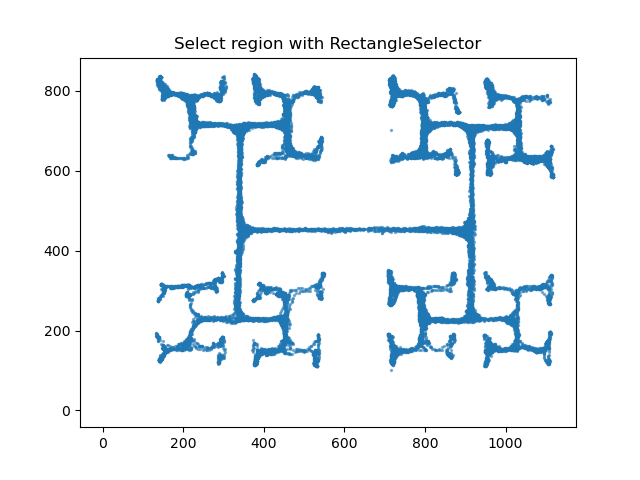

In [13]:
fig, ax = plt.subplots()
ax.scatter(dlc_updated['headstage']['x'], dlc_updated['headstage']['y'], s=2, alpha=0.5)
ax.set_title("Select region with RectangleSelector")
toggle_selector = RectangleSelector(ax, onselect, useblit=True,
                                   button=[1], minspanx=5, minspany=5, spancoords='pixels',
                                   interactive=True)
plt.show()

In [14]:
# After closing the plot, set likelihood to zero outside the selected box
def set_likelihood_to_zero_outside_boundary(df, bodypart, x_min, x_max, y_min, y_max):
    # Set likelihood to zero for rows where the bodypart is outside the bounding box
    mask = (
        (df[(bodypart, 'x')] < x_min) | (df[(bodypart, 'x')] > x_max) |
        (df[(bodypart, 'y')] < y_min) | (df[(bodypart, 'y')] > y_max)
    )
    df.loc[mask, (bodypart, 'likelihood')] = 0

if all(k in coords for k in ['x_min', 'x_max', 'y_min', 'y_max']):
    for part in bodyparts:
        set_likelihood_to_zero_outside_boundary(
            dlc_updated, part,
            coords['x_min'], coords['x_max'],
            coords['y_min'], coords['y_max']
        )
else:
    print("No rectangle was selected. Please run the cell again and select a region on the plot.")

In [15]:
for bodypart in bodyparts:
    set_likelihood_to_zero_outside_boundary(dlc_updated, bodypart, coords['x_min'], coords['x_max'], coords['y_min'], coords['y_max'])

In [16]:
N = 5
# Find the first index with N consecutive rows where all bodyparts have likelihood > 0
start_count = 0
start_zeros = 0
for i in range(len(dlc_updated)):
    if all(dlc_updated.loc[i, (bp, 'likelihood')] > 0 for bp in bodyparts):
        start_count += 1
        if start_count >= N:
            break
    else:
        start_count = 0
        start_zeros = i + 1  # index after the last zero row

# Find the last index with N consecutive rows where all bodyparts have likelihood > 0
end_count = 0
end_zeros = 0
for j in range(len(dlc_updated) - 1, -1, -1):
    if all(dlc_updated.loc[j, (bp, 'likelihood')] > 0 for bp in bodyparts):
        end_count += 1
        if end_count >= N:
            break
    else:
        end_count = 0
        end_zeros = len(dlc_updated) - j  # number of rows to drop from the end

print(f"Start zeros to drop: {start_zeros}, End zeros to drop: {end_zeros}")
# Drop the rows at the beginning and end
# dlc_updated = dlc_updated.iloc[start_zeros:len(dlc_updated)-end_zeros].reset_index(drop=True)

Start zeros to drop: 0, End zeros to drop: 0


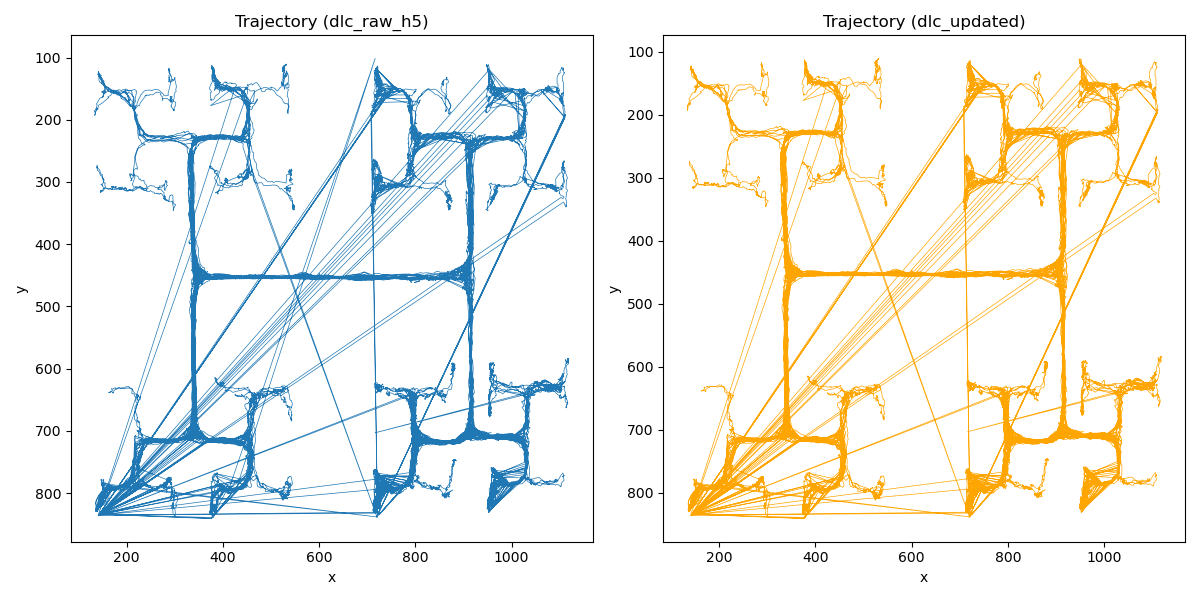

In [17]:
# Filter out rows where headstage likelihood is 0 for both dataframes
raw_mask = dlc_raw_h5['headstage']['likelihood'] > 0
updated_mask = dlc_updated['headstage']['likelihood'] > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].plot(
    dlc_raw_h5['headstage']['x'][raw_mask],
    dlc_raw_h5['headstage']['y'][raw_mask],
    lw=0.5
)
axes[0].set_title('Trajectory (dlc_raw_h5)')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].invert_yaxis()

axes[1].plot(
    dlc_updated['headstage']['x'][updated_mask],
    dlc_updated['headstage']['y'][updated_mask],
    lw=0.5,
    color='orange'
)
axes[1].set_title('Trajectory (dlc_updated)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [18]:
fixed_count = 0
total_out_of_bounds = 0

for i in range(len(dlc_updated)):
    if dlc_updated.loc[i, (bodypart, 'likelihood')] == 0:
        total_out_of_bounds += 1
        prev_idx = None
        next_idx = None
        # Search for previous frame with nonzero likelihood
        for offset in range(1, 10):
            idx = i - offset
            if idx >= 0 and dlc_updated.loc[idx, (bodypart, 'likelihood')] > 0:
                prev_idx = idx
                break
        # Search for next frame with nonzero likelihood
        for offset in range(1, 10):
            idx = i + offset
            if idx < len(dlc_updated) and dlc_updated.loc[idx, (bodypart, 'likelihood')] > 0:
                next_idx = idx
                break
        # If both found, interpolate
        if prev_idx is not None and next_idx is not None:
            x_val = (dlc_updated.loc[prev_idx, (bodypart, 'x')] + dlc_updated.loc[next_idx, (bodypart, 'x')]) / 2
            y_val = (dlc_updated.loc[prev_idx, (bodypart, 'y')] + dlc_updated.loc[next_idx, (bodypart, 'y')]) / 2
            likelihood_val = (dlc_updated.loc[prev_idx, (bodypart, 'likelihood')] + dlc_updated.loc[next_idx, (bodypart, 'likelihood')]) / 2

            dlc_updated.loc[i, (bodypart, 'x')] = x_val
            dlc_updated.loc[i, (bodypart, 'y')] = y_val
            dlc_updated.loc[i, (bodypart, 'likelihood')] = likelihood_val
            fixed_count += 1

print(f"Total out-of-bounds rows: {total_out_of_bounds}")
print(f"Rows fixed by interpolation: {fixed_count}")

Total out-of-bounds rows: 1
Rows fixed by interpolation: 1


In [19]:
%pip install mat73

Note: you may need to restart the kernel to use updated packages.


In [22]:
import scipy.io

In [23]:
trial_info = scipy.io.loadmat(r"C:\Users\Almog\Downloads\NPC1_14082025_1_trial_info.mat")
trial_times = trial_info['trial_info'][0][0][0]

In [25]:
trial_times

array([[62.0504    ],
       [62.05036667],
       [62.0503    ],
       [62.05026667],
       [62.05026667],
       [62.0502    ],
       [62.05026667],
       [62.05023333],
       [62.05023333],
       [62.0502    ],
       [62.05023333],
       [62.05023333],
       [62.05023333],
       [62.0502    ],
       [62.0502    ],
       [62.0502    ],
       [62.0502    ],
       [62.05016667],
       [62.0502    ],
       [62.05016667],
       [62.05016667],
       [62.05016667],
       [62.05016667],
       [62.0501    ],
       [62.05013333],
       [62.05013333],
       [62.05013333],
       [62.05016667],
       [62.05013333],
       [62.05013333],
       [44.4767    ],
       [13.8051    ],
       [ 6.14196667],
       [ 6.2557    ],
       [ 6.30603333],
       [ 8.13766667],
       [ 4.658     ],
       [ 6.56676667],
       [12.67326667],
       [ 6.23813333],
       [ 6.72843333],
       [ 7.00213333],
       [ 8.97836667],
       [12.88176667],
       [ 4.41616667],
       [ 8

In [24]:
trial_times_maze = trial_times[30:-31]
trial_times_maze

array([[44.4767    ],
       [13.8051    ],
       [ 6.14196667],
       [ 6.2557    ],
       [ 6.30603333],
       [ 8.13766667],
       [ 4.658     ],
       [ 6.56676667],
       [12.67326667],
       [ 6.23813333],
       [ 6.72843333],
       [ 7.00213333],
       [ 8.97836667],
       [12.88176667],
       [ 4.41616667],
       [ 8.25536667],
       [ 6.23683333],
       [ 6.2932    ],
       [ 6.51456667],
       [ 6.24313333],
       [11.53536667],
       [ 6.20433333],
       [18.5619    ],
       [ 8.01693333],
       [16.72616667],
       [ 6.46593333],
       [ 5.68743333],
       [ 6.34553333],
       [ 6.31746667],
       [ 7.31726667],
       [ 5.58546667],
       [ 4.23306667],
       [ 8.66956667],
       [ 9.10143333],
       [ 6.22896667],
       [ 6.22076667],
       [ 6.26836667],
       [ 6.6369    ],
       [ 5.37093333],
       [ 4.72493333],
       [ 6.23133333],
       [ 6.47563333],
       [ 6.37173333],
       [ 6.20973333],
       [ 4.18953333],
       [ 4

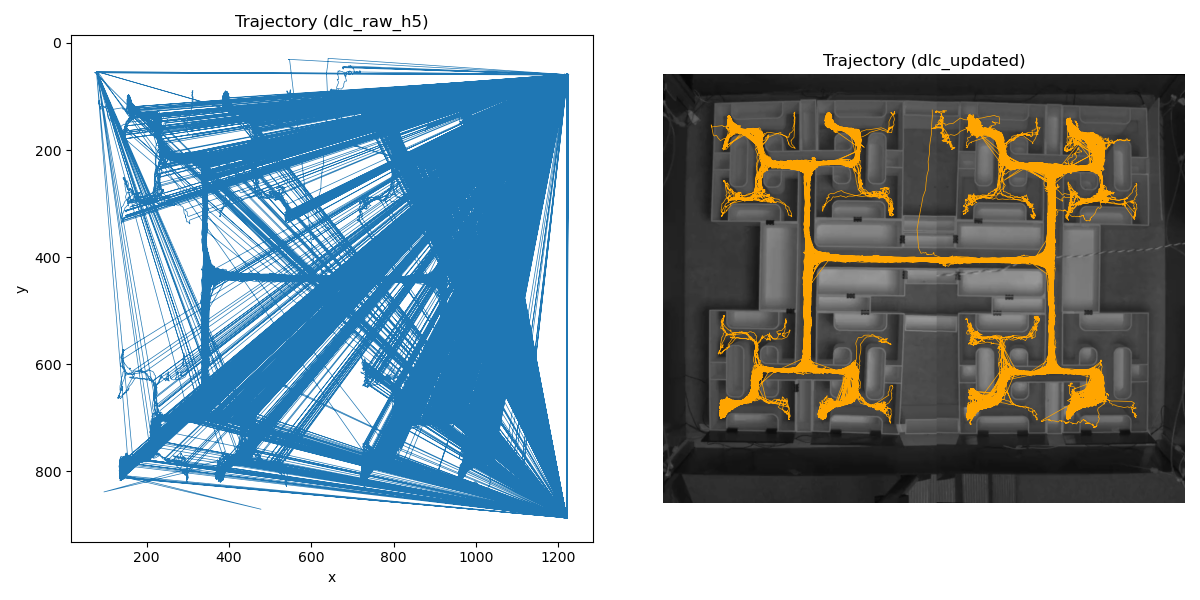

In [ ]:
maze_video_path = r"C:\Users\Almog\Desktop\Neuropixel_2Cams_Gamma-AnA_July-2025-07-22\videos\NPC1_2025_08_14_13_02_08_stitched_gamma.mp4"
#Extract image from video
import cv2
cap = cv2.VideoCapture(maze_video_path)
ret, frame = cap.read()
if ret:
    maze_image = frame
cap.release()

# plot the maze image
plt.imshow(cv2.cvtColor(maze_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [1]:
import os
import matplotlib.image as mpimg

def plot_trials(dlc_raw_h5, dlc_updated, trial_times_maze, updated_mask, save_dir, maze_img):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    fps = 40

    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        # Get x/y limits for the current trial (for cropping the image)
        x_vals = dlc_updated['headstage']['x'][start_idx:end_idx][updated_mask[start_idx:end_idx]]
        y_vals = dlc_updated['headstage']['y'][start_idx:end_idx][updated_mask[start_idx:end_idx]]
        if len(x_vals) == 0 or len(y_vals) == 0:
            continue
        x_min, x_max = x_vals.min(), x_vals.max()
        y_min, y_max = y_vals.min(), y_vals.max()

        # Add 20 pixels padding, but keep within image bounds
        x_min_pad = max(x_min - 20, 0)
        x_max_pad = min(x_max + 20, img_width)
        y_min_pad = max(y_min - 20, 0)
        y_max_pad = min(y_max + 20, img_height)

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        # Plot raw
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[0].plot(
            dlc_raw_h5['headstage']['x'][start_idx:end_idx][dlc_raw_h5['headstage']['likelihood'][start_idx:end_idx] > 0],
            dlc_raw_h5['headstage']['y'][start_idx:end_idx][dlc_raw_h5['headstage']['likelihood'][start_idx:end_idx] > 0],
            lw=0.5
        )
        axes[0].set_title(f'Trial {i+1} (dlc_raw_h5)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s')
        axes[0].invert_yaxis()
        axes[0].set_xlim(x_min_pad, x_max_pad)
        axes[0].set_ylim(y_max_pad, y_min_pad)

        # Plot updated
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[1].plot(
            x_vals,
            y_vals,
            lw=0.5,
            color='orange'
        )
        axes[1].set_title(f'Trial {i+1} (dlc_updated)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s')
        axes[1].invert_yaxis()
        axes[1].set_xlim(x_min_pad, x_max_pad)
        axes[1].set_ylim(y_max_pad, y_min_pad)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}.png"))
        plt.close(fig)

# Example usage:
plot_trials(
    dlc_raw_h5, dlc_updated, trial_times_maze, updated_mask,
    r"C:\Users\Almog\Desktop\trial_trajectories_maze_background",
    maze_image
)

NameError: name 'dlc_raw_h5' is not defined

In [140]:
dlc_updated[990:1020]

headstage                               ear_L                         \
                x           y likelihood            x           y likelihood   
990    996.361755  146.561584   0.736268   978.945190  141.147812   0.755490   
991    999.041931  146.493454   0.672059   983.010132  141.340073   0.659773   
992   1222.287109   59.582638   0.000000   985.538879  143.839615   0.441832   
993   1222.594482   59.571701   0.000000   989.392029  144.477676   0.380195   
994   1222.781250   59.814327   0.000000   991.690796  142.847076   0.506755   
995   1222.816772   59.885307   0.000000   994.826538  144.565887   0.486423   
996   1222.892090   59.844807   0.000000   999.164246  144.432297   0.583043   
997   1223.088867   59.692078   0.000000  1218.864624   64.209885   0.000000   
998   1222.882324   59.649879   0.000000  1011.338196  145.756516   0.500493   
999   1222.985352   59.730381   0.000000  1218.509888   64.207199   0.000000   
1000  1222.991455   59.829376   0.000000  1218.344360   63.578281   0.000000   
1001  1222.841309   59.721161   0.000000  1218.408081   64.077461   0.000000   
1002  1222.919067   59.925682   0.000000  1218.514282   64.361710   0.000000   
1003  1222.956421   59.897152   0.000000  1003.115112  149.989532   0.576225   
1004  1222.698853   60.008354   0.000000  1001.451294  154.231110   0.406941   
1005  1222.704834   59.745014   0.000000  1001.644043  152.476135   0.480647   
1006  1031.675781  199.234146   0.700934  1044.025757  184.673767   0.655867   
1007  1026.187500  210.094925   0.656998  1042.212646  193.292282   0.608336   
1008  1023.985168  213.418777   0.829299  1041.302856  200.058990   0.746489   
1009  1021.936890  214.409790   0.758817  1039.328979  206.196548   0.835517   
1010  1017.515503  220.025650   0.621739  1034.665405  213.728867   0.818674   
1011  1009.187195  222.720093   0.819520  1030.978149  219.947144   0.865036   
1012  1006.680786  222.633728   0.730975  1022.660278  223.720947   0.709319   
1013   997.532410  221.500824   0.630864  1013.077393  226.067078   0.523152   
1014   992.795471  221.272308   0.756607  1007.567627  226.397659   0.521397   
1015   981.270630  221.143158   0.842804   998.570251  226.253128   0.625810   
1016   973.405396  221.441193   0.748723   992.580627  225.119446   0.582684   
1017   965.622803  222.019089   0.860572   983.742249  228.019012   0.581710   
1018   945.930420  229.454010   0.852793   973.108765  221.167603   0.427885   
1019   936.084229  233.171478   0.848904  1219.393433   63.897366   0.000000   

            ear_R                             midbody                         \
                x           y likelihood            x           y likelihood   
990    981.830627  156.286652   0.698070   963.472961  155.007950   0.885624   
991    985.077332  155.881180   0.608830   964.905823  153.469788   0.860201   
992    985.468079  154.484879   0.440401   966.613647  152.847031   0.831362   
993   1233.278076   70.871040   0.000000   966.039246  153.122803   0.817736   
994    990.574585  153.759903   0.485119   966.001648  152.804367   0.752058   
995    996.556702  154.487793   0.406513   972.289246  153.302429   0.804279   
996    999.437866  155.457825   0.414685   980.325317  150.788406   0.956426   
997   1233.802734   70.818016   0.000000   987.499634  147.648865   0.840151   
998   1009.312866  157.281693   0.385990   992.414185  147.102951   0.911986   
999   1233.413818   70.714798   0.000000   999.975769  146.302383   0.815004   
1000  1233.165527   70.611427   0.000000  1005.565308  146.576416   0.850548   
1001  1233.143066   70.732719   0.000000  1010.212891  146.288895   1.000000   
1002  1233.210571   70.901169   0.000000  1017.903015  147.804703   1.000000   
1003  1010.463867  135.428482   0.536393  1019.715515  148.491272   0.852435   
1004  1007.593628  137.530746   0.399969  1023.002625  151.364105   0.898776   
1005  1009.193970  137.818161   0.484466  1023.633240  154.307663   0.916419   
1006  1

In [153]:
dlc_updated[dlc_updated['headstage']['likelihood'] == 0]

headstage                              ear_L                         \
                  x          y likelihood            x           y likelihood   
0       1225.746216  58.650742        0.0  1172.654541  938.546143   0.000000   
1       1223.666138  59.027889        0.0  1227.202393  895.803162   0.000000   
2       1223.600830  58.788288        0.0  1227.873291  895.815369   0.000000   
3       1223.532227  58.805294        0.0  1227.693848  895.700745   0.000000   
4       1223.592529  58.846447        0.0  1227.953125  895.617310   0.000000   
...             ...        ...        ...          ...         ...        ...   
203900  1223.717896  59.835934        0.0   975.892395  147.702057   0.498149   
203901  1223.756958  59.882473        0.0   972.796631  173.154663   0.505148   
204200  1222.627319  59.469452        0.0   968.074280  300.384735   0.380554   
205063  1222.979492  59.234760        0.0   959.064697  764.126526   0.440851   
205064  1223.173950  59.287937        0.0   963.186584  764.631897   0.344889   

              ear_R                            midbody                         \
                  x           y likelihood           x           y likelihood   
0       1229.988281   69.945328   0.000000  269.806732  860.644958   0.000000   
1       1229.722046   70.649147   0.000000  278.490997  859.902344   0.000000   
2       1229.945190   70.707748   0.000000  278.249176  859.757812   0.000000   
3       1230.006592   70.668343   0.000000  278.343353  859.932312   0.000000   
4       1229.897339   70.772102   0.000000  278.521606  860.028931   0.000000   
...             ...         ...        ...         ...         ...        ...   
203900   978.560608  160.114319   0.481285  961.988159  160.277634   0.875707   
203901   956.698181  174.880890   0.563310  964.456787  158.794357   0.999876   
204200  1232.323242   71.789917   0.000000  964.401367  306.338318   0.332724   
205063  1231.634521   70.368965   0.000000  970.805664  774.394348   0.927102   
205064  1231.580688   70.188652   0.000000  972.292969  777.235413   0.920964   

          tailbase                        weighted                 
                 x           y likelihood        x   y likelihood  
0       302.025085  100.989944   0.441331      NaN NaN        NaN  
1       101.449989  858.413940   0.000000      NaN NaN        NaN  
2       101.288437  858.461731   0.000000      NaN NaN        NaN  
3       101.383194  858.350952   0.000000      NaN NaN        NaN  
4       101.431572  858.378052   0.000000      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
203900  962.055847  181.975708   0.451563      NaN NaN        NaN  
203901  974.553406  143.254074   0.542869      NaN NaN        NaN  
204200  306.676636  858.725037   0.000000      NaN NaN        NaN  
205063  990.876587  777.534973   0.431232      NaN NaN        NaN  
205064  971.495056  759.343445   0.508203      NaN NaN        NaN  

[1493 rows x 18 columns]

In [ ]:
def calculate_weighted_coordinates(row):
    nose_likelihood = row['nose']['likelihood']
    head_stage_likelihood = row['head_stage']['likelihood']
    
    # If either nose or head_stage has a likelihood at least 0.6, pick the one with the higher likelihood.
    if nose_likelihood >= 0.6 or head_stage_likelihood >= 0.6:
        if nose_likelihood >= head_stage_likelihood:
            return (row['nose']['x'], row['nose']['y'], nose_likelihood)
        else:
            return (row['head_stage']['x'], row['head_stage']['y'], head_stage_likelihood)
    
    # Both nose and head_stage have low likelihood, so use weighted sum of all other body parts.
    body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base']
    total_weight = 0
    weighted_x = 0
    weighted_y = 0
    likelihoods = []

    for part in body_parts:
        likelihood = row[part]['likelihood']
        likelihoods.append(likelihood)
        if likelihood > 0:
            weighted_x += row[part]['x'] * likelihood
            weighted_y += row[part]['y'] * likelihood
            total_weight += likelihood

    if total_weight > 0:
        weighted_x /= total_weight
        weighted_y /= total_weight
        weighted_likelihood = sum(likelihood * (likelihood / total_weight) for likelihood in likelihoods)
    else:
        weighted_likelihood = 0

    return (weighted_x, weighted_y, weighted_likelihood)

for i, row in enumerate(dlc_raw_h5.iterrows()):
    dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# Display the updated dataframe
dlc_raw_h5

nose                               ear_L                         \
                x           y likelihood            x           y likelihood   
0      930.863403  250.882019   0.201783  1138.078735  423.674072   0.377326   
1      995.247681  229.974350   0.101296  1137.368652  424.024597   0.368687   
2      926.486694  261.117310   0.209730  1137.525269  423.668335   0.360559   
3      925.783569  260.580078   0.201815   938.498352  256.050842   0.414909   
4      925.632507  258.589050   0.181430   937.801636  255.904114   0.433897   
...           ...         ...        ...          ...         ...        ...   
52670  146.793533  132.550720   0.325325   150.772186  146.755646   0.417223   
52671  146.342316  132.174072   0.298409   149.939285  146.140671   0.450341   
52672  146.192795  131.492966   0.288205   149.705826  145.472641   0.473696   
52673  146.396698  131.411316   0.280032   149.407074  145.541229   0.456315   
52674  146.382507  131.423920   0.279323   149.399643  145.540253   0.455801   

            ear_R                           mid_body  ...             \
                x           y likelihood           x  ... likelihood   
0      935.880066  241.502914   0.378170  962.458496  ...   0.790137   
1      986.723694  236.377441   0.299528  953.868896  ...   0.787700   
2      930.504333  246.332520   0.452268  951.539062  ...   0.804729   
3      930.126343  245.383942   0.544846  951.739685  ...   0.790117   
4      928.336243  244.173874   0.507018  951.254395  ...   0.860785   
...           ...         ...        ...         ...  ...        ...   
52670  155.648575  137.741913   0.483237  167.702057  ...   0.995947   
52671  155.669800  137.067810   0.482478  166.821838  ...   0.985281   
52672  155.833298  136.576111   0.487797  166.816574  ...   0.977104   
52673  156.001068  136.763504   0.464179  166.374542  ...   0.973690   
52674  155.992279  136.761490   0.464027  166.373322  ...   0.973629   

         tail_base                          head_stage                         \
                 x           y likelihood            x           y likelihood   
0       931.504333  250.539566   0.554688  1234.689331  928.418213   0.000000   
1       926.760315  256.584137   0.685993  1234.713623  928.493652   0.000000   
2      1164.361328  436.043121   0.480829  1234.776733  928.549927   0.000000   
3       981.033569  231.014069   0.523580  1234.621460  928.349304   0.000000   
4       980.199829  230.937119   0.556051  1234.547607  928.377869   0.000000   
...            ...         ...        ...          ...         ...        ...   
52670   183.646530  152.012222   0.661626   151.734329  142.017899   0.372288   
52671   183.523849  152.230026   0.652700   150.617142  140.283203   0.345683   
52672   183.516800  152.270477   0.668461   149.806488  139.150513   0.322688   
52673   183.404236  152.316010   0.655666   150.240280  139.051407   0.313202   
52674   183.402084  152.314224   0.656043   150.234192  139.060226   0.313019   

          weighted                         
                 x           y likelihood  
0       981.048504  273.710844   0.579617  
1       981.367066  275.504449   0.614735  
2      1027.729483  316.801175   0.578223  
3       950.889791  241.274438   0.601476  
4       950.676782  240.674097   0.634281  
...            ...         ...        ...  
52670   166.787701  147.417750   0.718229  
52671   166.011931  147.564739   0.712769  
52672   165.934570  147.357884   0.714946  
52673   165.828683  147.628221   0.706573  
52674   165.831219  147.629365   0.706578  

[52675 rows x 21 columns]

In [154]:
# Restore the top level index (scorer) with the file name
h5_file = pd.concat({file_name: dlc_updated}, axis=1)
# Restore the index column names
h5_file.columns.names = ['scorer', 'bodyparts', 'coords']
h5_file

scorer    NPC1_2025_08_14_13_02_08_stitched_gammaDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle3_snapshot_150  \
bodyparts                                                                                             headstage   
coords                                                                                                        x   
0                                                1225.746216                                                      
1                                                1223.666138                                                      
2                                                1223.600830                                                      
3                                                1223.532227                                                      
4                                                1223.592529                                                      
...                                                      ...                                                      
205113                                            920.526733                                                      
205114                                            920.636597                                                      
205115                                            919.783875                                                      
205116                                            920.346497                                                      
205117                                            921.568604                                                      

scorer                                                                \
bodyparts                               ear_L                          
coords              y likelihood            x           y likelihood   
0           58.650742   0.000000  1172.654541  938.546143   0.000000   
1           59.027889   0.000000  1227.202393  895.803162   0.000000   
2           58.788288   0.000000  1227.873291  895.815369   0.000000   
3           58.805294   0.000000  1227.693848  895.700745   0.000000   
4           58.846447   0.000000  1227.953125  895.617310   0.000000   
...               ...        ...          ...         ...        ...   
205113     642.190735   0.857957   911.487671  657.983948   0.913761   
205114     634.909302   0.818240   912.046387  648.719788   0.878790   
205115     625.549255   0.927296   912.722107  643.703064   0.911139   
205116     617.812866   0.833715   911.399475  632.437439   0.866492   
205117     611.505493   0.823855   911.846497  627.164124   0.913876   

scorer                                                                 \
bodyparts        ear_R                            midbody               
coords               x           y likelihood           x           y   
0          1229.988281   69.945328   0.000000  269.806732  860.644958   
1          1229.722046   70.649147   0.000000  278.490997  859.902344   
2          1229.945190   70.707748   0.000000  278.249176  859.757812   
3          1230.006592   70.668343   0.000000  278.343353  859.932312   
4          1229.897339   70.772102   0.000000  278.521606  860.028931   
...                ...         ...        ...         ...         ...   
205113      931.593140  660.043640   0.933497  925.523438  684.174805   
205114      931.889465  653.111023   0.898839  925.250061  676.432678   
205115      931.763916  646.414734   0.832285  923.569580  670.815979   
205116      930.704834  634.988586   0.903648  923.122864  659.225769   
205117      931.593140  631.825439   0.848636  923.498840  654.304016   

scorer                                                                \
bodyparts               tailbase                        weighted       
coords    likelihood           x           y likelihood        x   y   
0           0.000000  302.025085  100.989944   0.441331      NaN NaN   
1           0.000000  101.449989  858.413940   0.000000      NaN NaN 

In [155]:
# Save the updated DataFrame back to the HDF5 file, update path and name as wish
h5_file.to_hdf(folder_path + file_name + '_updated.h5', key=file_name, mode='w')

In [64]:
import numpy as np
import pandas as pd

# List of body parts to check (excluding the reference 'mid_body')
body_parts = ['ear_R', 'ear_L', 'head_stage', 'nose', 'tail_base']

# Container for rows that are considered outliers.
outlier_rows = []

for index, row in dlc_raw_h5.iterrows():
    # Use nose coordinates as the reference point.
    ref_x = row['mid_body']['x']
    ref_y = row['mid_body']['y']
    
    # Variable to hold the outlier body part (if any)
    outlier_body = None
    
    # Check each body part
    for part in body_parts:
        dx = row[part]['x'] - ref_x
        dy = row[part]['y'] - ref_y
        distance = np.sqrt(dx**2 + dy**2)
        if distance > 300:
            outlier_body = part
            break
            
    if outlier_body:
        # Make a copy of the row and add the outlier body part information.
        new_row = row.copy()
        new_row['outlier_body'] = outlier_body
        outlier_rows.append(new_row)

outliers_df = pd.DataFrame(outlier_rows)
print("Found", len(outliers_df), "outlier rows.")

Found 21495 outlier rows.


In [13]:
outliers_df

nose                              ear_L                          \
                 x           y likelihood           x            y likelihood   
0       357.991852  102.027466   0.096844  172.259048   631.571716   0.170674   
1       357.991852  102.027466   0.132439  697.261047  1016.736267   0.000000   
2       357.991852  102.027466   0.126299  698.825134  1016.744507   0.000000   
3       357.771729  100.034554   0.118914  698.842468  1016.744507   0.000000   
4       357.589417  100.034554   0.130283  698.871460  1016.740295   0.000000   
...            ...         ...        ...         ...          ...        ...   
106269  357.377411  100.441414   0.120484  357.336548   116.402100   0.108573   
106270  357.373993  100.430611   0.119981  357.336548   116.405815   0.109413   
106271  357.392914  100.430611   0.115607  357.340393   116.405815   0.108022   
106272  357.392914  100.316513   0.102566  357.340393   116.402100   0.100664   
106273  357.295258   99.633568   0.102977  357.030273   116.397072   0.100811   

             ear_R                            mid_body  ...   tail_base  \
                 x            y likelihood           x  ...           x   
0       690.456421   408.303253   0.176608  155.626831  ...  147.016876   
1       692.241333  1022.014832   0.000000  674.115295  ...  654.800903   
2       692.244202  1022.014832   0.000000  674.404846  ...  655.694092   
3       692.244202  1022.016174   0.000000  674.413818  ...  655.696899   
4       692.523621  1022.037292   0.000000  674.413818  ...  655.807129   
...            ...          ...        ...         ...  ...         ...   
106269  365.039001   101.905685   0.203116  151.276947  ...  147.032730   
106270  365.039001   101.899910   0.203860  151.276031  ...  147.031937   
106271  365.015869   101.899910   0.200736  151.276947  ...  147.016418   
106272  364.862885   101.845116   0.188698  151.276947  ...  146.916824   
106273  364.720276   101.725418   0.187232  151.133591  ...  146.659332   

                                head_stage                           weighted  \
                  y likelihood           x           y likelihood           x   
0        666.511353   0.282438  377.326202  110.977829   0.240855  285.163397   
1       1016.053345   0.000000  377.326202  111.512482   0.344913  377.326202   
2       1016.053345   0.000000  377.345459  111.512482   0.308613  377.345459   
3       1016.053345   0.000000  377.326202  111.512482   0.329658  377.326202   
4       1015.923035   0.000000  377.246918  111.512695   0.315672  377.246918   
...             ...        ...         ...         ...        ...         ...   
106269   666.404053   0.188263  378.127625  110.936340   0.391155  378.127625   
106270   666.404053   0.188591  378.127625  110.937164   0.388132  378.127625   
106271   666.403625   0.195708  378.127625  110.946671   0.386863  378.127625   
106272   666.399536   0.215461  378.004211  110.937164   0.359986  378.004211   
106273   666.370300   0.193566  377.985626  110.937164   0.372175  377.985626   

                              outlier_body  
                 y likelihood               
0       499.923756   0.238662        ear_R  
1       111.512482   0.344913   head_stage  
2       111.512482   0.308613   head_stage  
3       111.512482   0.329658   head_stage  
4       111.512695   0.315672   head_stage  
...            ...        ...          ...  
106269  110.936340   0.391155        ear_R  
106270  110.937164   0.388132        ear_R  
106271  110.946671   0.386863        ear_R  
106272  110.937164   0.359986        ear_R  
106273  110.937164   0.372175        ear_R  

[21495 rows x 22 columns]

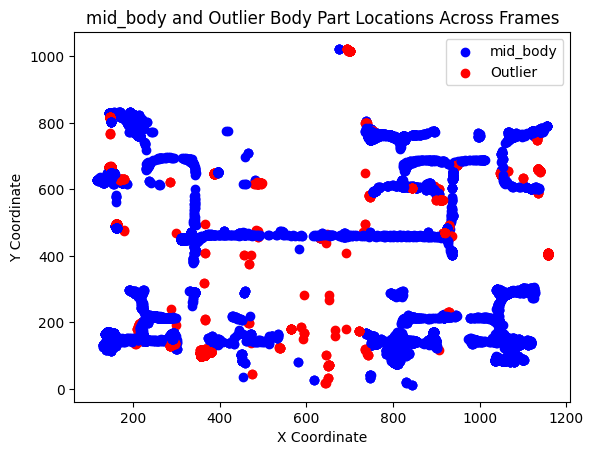

In [14]:
import matplotlib.pyplot as plt

# Iterate through each row in the outliers_df
for index, row in outliers_df.iterrows():
    # Extract the nose and outlier body part coordinates
    nose_x, nose_y = row['mid_body']['x'], row['mid_body']['y']
    outlier_body = row['outlier_body'].to_string().replace(' ', '')
    outlier_x, outlier_y = row[outlier_body]['x'], row[outlier_body]['y']
    
    # Plot the nose and outlier body part
    plt.scatter(nose_x, nose_y, color='blue', label='mid_body' if index == 0 else "")
    plt.scatter(outlier_x, outlier_y, color='red', label='Outlier' if index == 0 else "")

# Add labels and legend
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.title('mid_body and Outlier Body Part Locations Across Frames')
plt.legend()
plt.show()